# B? SUNG ? REFERENCE EXTRACTION (TR?CH XU?T T?I LI?U THAM KH?O)

## M?c ti?u v? v? tr? trong pipeline

Reference Extraction chuy?n c?c ngu?n tham kh?o kh?c nhau c?a t?ng publication/version th?nh danh s?ch entry c? c?ng schema ?? b??c Reference Deduplication c? th? so kh?p v? h?p nh?t. Trong `src/parser/dedup.py`, ph?n n?y ???c ??t trong `ReferenceDeduplicator`; kh?ng c? m?t l?p `ReferenceExtractor` ri?ng. ?i?m ?i?u ph?i to?n pipeline l? `PublicationDeduplicator.deduplicate_and_save_publication(pub_dir)`: n?p d? li?u c?c version, thu th?p references, chu?n h?a/kh? tr?ng l?p BibTeX, c?p nh?t citation keys trong elements, r?i l?u c?c b?ng k?t qu?.

## 1. Ngu?n d? li?u ??u v?o

`ReferenceDeduplicator.load_publication_references(pub_dir, version_names)` ??c tham kh?o theo publication v? phi?n b?n. Th? t? x? l? ch?nh:

1. **JSON theo version trong `<pub_dir>/bibtex/`:** th? `bibtex_<version>.json`, `references_<version>.json`, r?i `<version>.json`. N?u JSON parse ???c th?nh m?t list, c?c dictionary ???c chu?n h?a (entry thi?u citation key b? b?) v? version ???c ??nh d?u ?? n?p k? c? khi list r?ng ho?c kh?ng c?n entry h?p l?; c?c ngu?n `.bib`/`\bibitem` theo version s? kh?ng ???c qu?t l?i.
2. **JSON t?ng h?p tr??c dedup:** th? `raw_bibtex.json`, `bibtex_raw.json`, ho?c `all_references.json` trong th? m?c `bibtex/`, khi ch?a thu ???c entry n?o t? ngu?n tr??c ??.
3. **Ngu?n c?a b??c Hierarchy Construction:** ??c `<pub_dir>/elements/raw_references.json` theo version v? d?ng danh s?ch `bibitem_entries` n?u c?. T?p n?y ???c t?o/gi? l?i ? b??c parse LaTeX tr??c ??; c?u tr?c record c? th? g?m `thebibliography_blocks`, `bibitem_entries`, `bibliography_commands` v? `reference_sections`.
4. **T? qu?t theo version n?u ch?a c? JSON theo version:** ??c ?? quy c?c file `.bib` trong `<pub_dir>/<version>/`. Khi c? nhi?u file, t?n template nh? `sample-base`, `ws-pro-sample`, `acmart-sample` ???c lo?i n?u c?n file kh?c. ??ng th?i, n?u ch?a c? `bibitem_entries` t? JSON, t?m trong `elements/full_inlined_<version>.tex`; n?u kh?ng c? th? t?m c?c `.tex` trong th? m?c version, ch? l?y `\bibitem` thu?c m?i tr??ng `thebibliography` ho?c `references`.
5. **Fallback cu?i:** n?u to?n b? danh s?ch v?n r?ng, ??c c?c file `.bib` tr?c ti?p trong `<pub_dir>/bibtex/`, r?i th? `<pub_dir>/bibtex/bibtex.json`.

C?c file CSV l? **??nh d?ng ??u ra** trong pipeline hi?n t?i; `load_publication_references` kh?ng d?ng CSV l?m ngu?n ??u v?o.

## 2. L?p v? c?c h?m tr?ch xu?t/chu?n h?a ch?nh

### `ReferenceDeduplicator`

L?p n?y ch?u tr?ch nhi?m n?p nhi?u ??nh d?ng, ??a ch?ng v? schema chu?n, r?i cung c?p d? li?u cho b??c g?p tham kh?o:

- **`load_publication_references(...)`** ? ?i?u ph?i vi?c ??c JSON theo version, JSON t?ng h?p, `.bib`, `raw_references.json` v? `.tex`; tr? v? danh s?ch entry th? ?? chu?n h?a c? b?n.
- **`parse_bib_content(bib_text, arxiv_id, version)`** ? ph?n t?ch c?c entry `@type{key, ...}` trong file `.bib`. B? comment d?ng `%`, b? qua `@string`, `@preamble`, `@comment`, ??c ranh gi?i entry v? t?ng gi? tr? field. H?m t?o title, authors, year, DOI, journal/venue v? URL; n?u thi?u URL nh?ng c? `eprint` d?ng arXiv th? d?ng URL `https://arxiv.org/abs/...`.
- **`_extract_balanced_value(text, start_pos)`** ? helper ??c gi? tr? BibTeX d?ng `{...}` c? ngo?c l?ng nhau, chu?i c? d?u nh?y, ho?c gi? tr? tr?n. Nh? v?y d?u ngo?c b?n trong title kh?ng l?m k?t th?c field qu? s?m.
- **`parse_bibitem_entries(bibitems, arxiv_id, version)`** ? chuy?n t?ng `\bibitem` th?nh entry chu?n. Regex nh?n citation key v? n?i dung (c? h? tr? nh?n t?y ch?n `[...]`). Ph?n n?i dung ???c l?m s?ch comment/kho?ng tr?ng, d? URL/DOI/n?m, r?i t?ch t?c gi??ti?u ???venue theo `\newblock`, ph?n in nghi?ng/??t trong d?u nh?y, ??nh d?ng thi?n v?n theo t?c gi?-n?m, ho?c heuristic d?u ch?m. `entry_type` ???c suy ?o?n t? n?i dung (v? d? conference/proceedings, book, thesis, journal; n?u kh?ng x?c ??nh th? `misc`). ??y l? tr?ch xu?t heuristic v? v?n b?n `\bibitem` kh?ng c? c?u tr?c field chu?n nh? BibTeX.
- **`standardize_entry_dict(raw, arxiv_id, default_version)`** ? chu?n h?a entry ?? c? trong JSON v? c?ng schema, ch?p nh?n alias nh? `key`/`id`, `type`/`ENTRYTYPE`, `author`, `DOI`/`URL`; b? entry kh?ng c? citation key.
- **C?c helper chu?n h?a:** `strip_latex_accents_and_braces` b? d?u/format LaTeX ph? bi?n; `clean_display_title` l?m s?ch title/venue; `parse_authors_list` chu?n h?a author th?nh danh s?ch t?n; `parse_year_int` l?y n?m 4 ch? s? trong kho?ng 1800?2035; `normalize_doi` b? ti?n t? DOI URL/`doi:` v? ki?m tra d?ng c? b?n; `normalize_title_key` t?o kh?a title ch?-s? vi?t th??ng ph?c v? so kh?p.

## 3. Schema d? li?u v? lu?ng x? l?

C?c parser tr? m?i tham kh?o v? m?t dictionary c? c?c tr??ng:

| Tr??ng | N?i dung / ki?u |
| :--- | :--- |
| `arxiv_id` | ID publication (`string`) |
| `version` | Version ngu?n (`string`, v? d? `v1`) |
| `citation_key` | Kh?a tr?ch d?n g?c (`string`) |
| `entry_type` | Lo?i entry BibTeX (`string`, m?c ??nh `misc` n?u kh?ng x?c ??nh) |
| `title` | Ti?u ?? ?? l?m s?ch (`string`) |
| `authors` | Danh s?ch t?n t?c gi? (`list[string]`) |
| `year` | N?m xu?t b?n (`int` ho?c `null`) |
| `doi` | DOI chu?n h?a ho?c chu?i r?ng |
| `journal` | T?p ch?/venue/publisher ?? l?m s?ch |
| `url` | URL tham kh?o, ho?c chu?i r?ng |

Lu?ng x? l? t? ??u v?o ??n ??u ra:

```text
bibtex JSON / .bib / raw_references.json / .tex
                ?
                ?
load_publication_references
                ?  parse_bib_content / parse_bibitem_entries
                ?  standardize_entry_dict + chu?n h?a field
                ?
Danh s?ch raw entries th?ng nh?t (arxiv_id, version, citation_key, ...)
                ?
                ?
deduplicate_bibtex ? BibTeX h?p nh?t + key_mapping
                ?
                ??? rewrite_citations_in_elements: ??i key c? th?nh canonical key
                ??? ElementDeduplicator: ti?p t?c dedup n?i dung sau khi citation ??ng b?
```

`deduplicate_bibtex` gom entry tr?ng theo DOI chu?n h?a, title chu?n h?a k?m ki?m tra an to?n v? n?m/t?c gi?, ho?c citation key t??ng th?ch. M?i c?m ch?n key xu?t hi?n ??u ti?n l?m canonical key (th?m nh?n version n?u key ?? ???c d?ng cho m?t c?m kh?c), sau ?? `unionize_cluster` ch?n/h?p nh?t c?c field c? th?ng tin ??y ?? h?n. K?t qu? g?m `bibtex`, `key_mapping`, chi ti?t c?m ?? g?p v? th?ng k?. `rewrite_citations_in_text`/`rewrite_citations_in_elements` ?p mapping v?o c?c l?nh citation h? tr? (`\cite`, `\citep`, `\citet`, `\parencite`, `\textcite`, ...), ??ng th?i b? key l?p trong c?ng m?t l?nh. Vi?c ??ng b? citation di?n ra tr??c full-text dedup ?? n?i dung ch? kh?c citation key v?n c? th? so kh?p ch?nh x?c.

## 4. ??u ra ???c l?u

K?t qu? cu?i c?a publication ???c ghi b?i `PublicationDeduplicator.deduplicate_and_save_publication`:

- **BibTeX ?? h?p nh?t:** `<pub_dir>/bibtex/bibtex.json` v? b?n sao `<pub_dir>/elements/bibtex.json`; schema cu?i g?m `arxiv_id`, `citation_key`, `entry_type`, `title`, `authors`, `year`, `doi`, `journal`, `url`.
- **?nh x? key:** `<pub_dir>/bibtex/citation_key_mapping.json`, ?nh x? citation key c? sang canonical key ?? c?p nh?t n?i dung tr?ch d?n.
- **??nh d?ng b?ng b? sung:** `bibtex.csv`/`bibtex.parquet` (c?ng c?c b?ng `elements` v? `hierarchy`) ???c t?o khi m?i tr??ng c? pandas v? h? tr? Parquet.
- **Th?ng k?:** `<pub_dir>/elements/dedup_stats.json` ghi s? entry tr??c/sau dedup, s? b?n ghi b? lo?i, key ??i t?n, field ???c b? sung v? chi ti?t c?m ???c g?p.

V? v?y, extraction kh?ng ch? ??c ri?ng `\bibitem`: pipeline h?p nh?t d? li?u ?? chu?n b?, file BibTeX v? ngu?n LaTeX theo version, chu?n h?a t?t c? v? c?ng schema, r?i m?i deduplicate v? ??ng b? citation keys.


# BÁO CÁO MILESTONE 2 — REFERENCE & FULL-TEXT DEDUPLICATION
**Thành viên thực hiện:** Lê Tuấn Kiệt - 24120080 
**Nhiệm vụ:** Khử trùng lặp cho Reference Entries (`bibtex`) và Full-text Content (`elements`, `hierarchy`), đồng bộ lệnh trích dẫn `\cite{...}` và cập nhật cây phân cấp `hierarchy_tree.json` cho từng version của các publications.  
**Nhóm:** Nhóm 11 — Nhập môn Khoa học Dữ liệu

---

## 1. Luồng Hoạt Động & Luồng Dữ Liệu (Data & Execution Workflow)

Trong quy trình xử lý 4 bước của nhóm, **Deduplication** là mắt xích hoàn thiện cuối cùng để kết nối dữ liệu của tất cả các phiên bản (`v1, v2, ...`) trong từng bài báo (`publication`) thành 3 bảng dữ liệu chuẩn không trùng lặp (`elements`, `hierarchy`, `bibtex`) và cập nhật lại cây phân cấp của từng version:

```text
[Đầu vào từ các bước trước]
   ├── <pub_dir>/elements/elements_vX.json & hierarchy_vX.json (Các phần tử & nhánh theo từng version)
   ├── <pub_dir>/vX/hierarchy_tree.json                        (Cây phân cấp ban đầu của Tân)
   └── <pub_dir>/bibtex/ & elements/raw_references.json        (Các mục BibTeX & \bibitem)
          │
          ▼
[Bước 4 - Reference & Full-text Deduplication (src/parser/dedup.py & src/run_dedup.py)]
   ├── Giai đoạn 1: Khử trùng lặp Reference Entries (ReferenceDeduplicator)
   │      ├── 1.1. Tải toàn bộ entries từ mọi version (v1, v2, ...) của bài báo
   │      ├── 1.2. Gom cụm trùng lặp 3 tầng bằng cấu trúc Union-Find (Disjoint Set):
   │      │         • Tầng 1: Khớp chính xác DOI đã chuẩn hóa (norm_doi)
   │      │         • Tầng 2: Khớp chính xác Title chuẩn hóa (norm_title >= 15 ký tự) + Kiểm tra Họ tác giả / Năm
   │      │         • Tầng 3: Khớp cùng citation_key xuyên version (nếu nội dung không mâu thuẫn)
   │      ├── 1.3. Chọn 1 khóa đại diện (canonical_key) & tạo bảng ánh xạ key_mapping (old_key -> canonical_key)
   │      └── 1.4. Hợp nhất trường (Field Unionization): gộp entry_type, title, authors, year, doi, journal, url
   │
   ├── Giai đoạn 2: Đồng bộ lệnh trích dẫn \cite{...} trong văn bản (Trước khi dedup Full-text)
   │      └── Quét toàn bộ elements của mọi version, thay thế old_key -> canonical_key trong 14 loại lệnh
   │          (\cite, \citep, \citet, \parencite...) và khử trùng lặp các key nằm chung trong cùng 1 lệnh \cite
   │
   └── Giai đoạn 3: Khử trùng lặp Full-text Content & Cập nhật Cây Hierarchy (ElementDeduplicator)
          ├── 3.1. Chuẩn hóa nội dung (sau cleanup & đổi \cite) và đối sánh xuyên suốt các version v1, v2...
          ├── 3.2. Bảo toàn cấu trúc cây phân cấp:
          │         • Mỗi version giữ 1 nút gốc Document riêng (<arxiv_id>#root1, #root2...)
          │         • Khối danh sách (itemize) định danh bằng chữ ký tổng hợp các mục \item con trực thuộc
          │         • Các tiêu đề trùng tên trong cùng 1 version được phân biệt theo thứ tự xuất hiện
          ├── 3.3. Ánh xạ lại bảng nhánh hierarchy (version kiểu int, parent_id non-null, loại bỏ nhánh lặp)
          └── 3.4. Cập nhật ngược element_id dùng chung vào cây <pub_dir>/vX/hierarchy_tree.json của từng version
          │
          ▼
[Đầu ra hoàn chỉnh sau bước 4]
   ├── <pub_dir>/bibtex/bibtex.{json,csv,parquet}              (Bảng BibTeX thống nhất đã khử trùng & hợp nhất trường)
   ├── <pub_dir>/bibtex/citation_key_mapping.json              (Từ điển ánh xạ old_key -> canonical_key)
   ├── <pub_dir>/elements/elements.{json,csv,parquet}          (Bảng Elements duy nhất xuyên version)
   ├── <pub_dir>/elements/hierarchy.{json,csv,parquet}         (Bảng nhánh Hierarchy xuyên version)
   ├── <pub_dir>/vX/hierarchy_tree.json                        (Cây phân cấp từng version đã cập nhật ID sau dedup)
   └── src/dedup_summary_stats.json                            (Thống kê toàn cục trước & sau Deduplication)
```

> **Note:** Việc khử trùng lặp Reference Entries và đổi tên lệnh `\cite{...}` **bắt buộc phải thực hiện trước** khi khử trùng lặp Full-text Content. Ví dụ: ở `v1` câu văn viết `"...see \cite{Ri14}."` và ở `v2` tác giả đổi tên khóa thành `"...see \cite{riehl}."`. Khi đồng bộ `\cite{Ri14} -> \cite{riehl}` trước, hai câu văn ở `v1` và `v2` trở nên giống hệt nhau 100% và được gộp về duy nhất một `element_id`!

## 2. Các Thư Viện & Công Cụ Sử Dụng

| Thư viện / Module | Chức năng trong phần Reference & Full-text Deduplication |
| :--- | :--- |
| `re` (Regular Expressions) | Chuẩn hóa chuỗi tiêu đề/DOI, phân tích cú pháp `.bib` có ngoặc nhọn lồng nhau và `\bibitem`, nhận diện 14 biến thể lệnh trích dẫn (`\cite`, `\citep`, `\citet`, `\parencite`...) có tham số tùy chọn `[...]` để đổi tên khóa trích dẫn. |
| `json` & `pathlib.Path` | Đọc và ghi đồng bộ dữ liệu JSON (`elements.json`, `hierarchy.json`, `bibtex.json`, `hierarchy_tree.json`, `dedup_stats.json`) xuyên suốt 50 thư mục bài báo và 83 thư mục version. |
| `pandas` & `pyarrow` | Xuất 3 bảng dữ liệu chuẩn (`elements`, `hierarchy`, `bibtex`) sang định dạng `.csv` và `.parquet`, đồng thời phục vụ tổng hợp bảng biểu thống kê trong báo cáo. |
| `matplotlib.pyplot` | Trực quan hóa các biểu đồ so sánh số lượng Elements và Reference Entries trước/sau khi khử trùng lặp trên toàn bộ 50 bài báo. |
| `src/parser/dedup.py` | Module lõi chứa 3 lớp: `ReferenceDeduplicator` (khử trùng lặp BibTeX, union trường, đổi tên `\cite`), `ElementDeduplicator` (khử trùng lặp Full-text & ánh xạ nhánh `hierarchy`), và `PublicationDeduplicator` (điều phối cập nhật cây `hierarchy_tree.json` từng version). |
| `src/run_dedup.py` | Script CLI chạy toàn bộ quy trình Deduplication trên 50 bài báo và xuất file thống kê tổng hợp `src/dedup_summary_stats.json`. |

## 3. Giải Thích Chi Tiết Các File Nguồn & Thuật Toán Khử Trùng Lặp

### 3.1. Lớp `ReferenceDeduplicator` trong [`src/parser/dedup.py`](../src/parser/dedup.py)

Lớp `ReferenceDeduplicator` giải quyết bài toán chuẩn hóa và khử trùng lặp tài liệu tham khảo ở cả 2 phạm vi: **bên trong cùng một version** (ví dụ tác giả gộp nhiều file `.bib` hoặc khai báo lặp mục tham khảo với 2 key khác nhau) và **xuyên suốt các version `v1, v2, ...`** của cùng một bài báo:

1. **Hàm `load_publication_references(pub_dir, version_names)` — Thu thập & Chuẩn hóa đầu vào đa nguồn:**
   - Đọc linh hoạt các dữ liệu BibTeX từ thư mục `<pub_dir>/bibtex/`, các file `.bib` trong từng version (tự động loại bỏ các file `.bib` mẫu của template như `sample-base.bib`, `ws-pro-sample.bib` nếu bài báo có file `.bib` chính), và các mục `\bibitem` trong `elements/raw_references.json`.
   - Bộ phân tích `parse_bib_content` sử dụng thuật toán **đếm độ sâu ngoặc nhọn (`depth` counter)** để đọc chính xác các tiêu đề chứa ký tự đặc biệt LaTeX lồng nhau (như `\"{a}` hay `{{LLM}}`) mà không bị cắt cụt.

2. **Hàm `_are_entries_same_reference(e1, e2)` & `deduplicate_bibtex(arxiv_id, raw_entries)` — Thuật toán Gom cụm 3 Tầng với Union-Find:**
   - Mỗi bản ghi tài liệu tham khảo được trích xuất 3 khóa chuẩn hóa: `norm_doi` (chữ thường, cắt bỏ tiền tố `https://doi.org/`), `norm_title` (loại bỏ dấu LaTeX, lệnh định dạng, ngoặc nhọn và chỉ giữ ký tự chữ-số `[a-z0-9]`), và tập hợp họ tác giả `_surnames`.
   - Sử dụng cấu trúc dữ liệu **Union-Find (Disjoint Set)** kết hợp bảng băm (Hash Buckets) để gom cụm các bản ghi trùng lặp với độ phức tạp gần tuyến tính:
     - **Tầng 1 (DOI Match):** Hai bản ghi đều có `norm_doi` hợp lệ và bằng nhau tuyệt đối $\rightarrow$ Gộp vào cùng cụm.
     - **Tầng 2 (Normalized Title Match + Chốt chặn an toàn):** Hai bản ghi có `norm_title` giống hệt nhau (độ dài $\ge 15$ ký tự, không thuộc danh sách tiêu đề mẫu như *"Article Title"* hay *"Manuscript in preparation"*), **đồng thời** năm xuất bản không lệch quá 2 năm (chống gộp nhầm 2 bài khác nhau cùng chuỗi tiêu đề ở 2 thập kỷ khác nhau) và có ít nhất 1 họ tác giả chung.
     - **Tầng 3 (Citation Key Match across versions):** Hai bản ghi ở các version khác nhau có cùng `citation_key` và nội dung tương thích (không mâu thuẫn tiêu đề/tác giả).

3. **Hàm `unionize_cluster(arxiv_id, cluster, canonical_key)` — Hợp nhất trường (Field Unionization):**
   - Chọn `citation_key` xuất hiện đầu tiên trong cụm làm khóa chuẩn `canonical_key`, ghi nhận mọi khóa còn lại vào từ điển `key_mapping[old_key] = canonical_key`.
   - Hợp nhất toàn bộ 7 trường thông tin (`entry_type`, `title`, `authors`, `year`, `doi`, `journal`, `url`) từ mọi bản ghi trong cụm:
     - `entry_type`: Ưu tiên kiểu cụ thể (`article`, `inproceedings`, `book`) hơn kiểu chung (`misc`).
     - `title` & `authors`: Chọn phiên bản có tiêu đề và danh sách tên tác giả đầy đủ nhất.
     - `year`, `doi`, `url`: Bổ sung các giá trị bị khuyết (ví dụ bản 1 có `year` nhưng thiếu `doi`, bản 2 có `doi` $\rightarrow$ bản hợp nhất có đủ cả hai).
     - `journal`: Nếu ở `v1` bài tham khảo ghi là *"arXiv preprint"* và sang `v2` được cập nhật thành tên tạp chí/hội nghị chính thức, hàm ưu tiên giữ tên tạp chí/hội nghị chính thức.

4. **Hàm `rewrite_citations_in_elements(version_parsed_data, key_mapping)` — Đổi tên lệnh `\cite{...}` trong văn bản:**
   - Dùng biểu thức chính quy `CITE_COMMAND_PATTERN` bắt chính xác 14 lệnh trích dẫn thực tế (`\cite`, `\citep`, `\citet`, `\citealt`, `\citealp`, `\citeauthor`, `\citeyear`, `\citepalias`, `\citetalias`, `\parencite`, `\textcite`, `\autocite`, `\nocite`, `\hyperlinkcite`), hỗ trợ cả tham số phụ `\citep[e.g.,][p.~5]{k1, k2}`.
   - Thay thế mọi `old_key` bằng `canonical_key` và **tự động loại bỏ các key trùng nhau nằm trong cùng một cặp ngoặc `{}`** (ví dụ `\cite{Kabashin2009, kabashin2009phase}` $\rightarrow$ `\cite{Kabashin2009}`).

---

### 3.2. Lớp `ElementDeduplicator` & `PublicationDeduplicator` trong [`src/parser/dedup.py`](../src/parser/dedup.py)

1. **Khử trùng lặp Full-text sau khi đã làm sạch (`ensure_cleaned_content`):**
   - Trước khi so khớp, nội dung từng phần tử được chuẩn hóa công thức toán (`$...$`, `\begin{equation}...`), loại bỏ các lệnh trình bày dư thừa và chuẩn hóa khoảng trắng, đồng thời đã được đồng bộ lệnh `\cite{...}`.
2. **Bảo toàn cấu trúc Cây Phân Cấp (Chống chập nhánh trung gian):**
   - **Nút gốc `document`:** Mỗi version $v$ giữ riêng một nút gốc `<arxiv_id>#root<v>` (`Version 1 root`, `Version 2 root`).
   - **Khối danh sách `itemize`:** Vì bản thân thẻ `\begin{itemize}...\end{itemize}` không chứa văn bản riêng, nếu chỉ so khớp theo chuỗi `content` thì mọi danh sách trong cùng một bài báo sẽ bị gộp nhầm thành 1 node `#list1` duy nhất. `ElementDeduplicator` khắc phục triệt để bằng cách tạo **chữ ký tổng hợp từ nội dung các mục `\item` con trực tiếp** (`list_body_sig`). Nhờ đó, các danh sách khác nhau trong cùng 1 version có ID riêng biệt (`#list1`, `#list2`...), nhưng danh sách giữ nguyên qua `v1` và `v2` vẫn dùng chung đúng 1 ID `#list1`!
   - **Các nút lá (`sentence`, `block_formula`, `figure`, `item`):** So khớp chính xác theo `(kind, norm_text)` xuyên suốt mọi version để dùng chung 1 `element_id` duy nhất.
3. **Cập nhật ngược vào cây `hierarchy_tree.json` của từng version:**
   - Sau khi gộp `elements` và ánh xạ lại các nhánh `(arxiv_id, version, element_id, parent_id)`, lớp `PublicationDeduplicator` gọi `HierarchyBuilder.build_nested_tree` để cập nhật trực tiếp các `element_id` dùng chung vào `<pub_dir>/vX/hierarchy_tree.json` và `<pub_dir>/elements/hierarchy_tree_vX.json`.

In [1]:
# Minh họa trực tiếp cơ chế hoạt động của ReferenceDeduplicator & ElementDeduplicator
import sys
import json
import pandas as pd
from pathlib import Path

project_root = Path.cwd().parent if Path.cwd().name == "reports" else Path.cwd()
src_dir = project_root / "src"
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

from parser.dedup import ReferenceDeduplicator, ElementDeduplicator

# Giả sử có 1 bài báo (2310.12345) qua 3 versions:
# - Version 1 dùng key 'vaswani2017' (có title, authors, year=2017 nhưng thiếu doi & journal)
# - Version 2 đổi tên key thành 'vit_transformer' (thêm doi & journal nhưng thiếu year)
sample_raw_bib = [
    {
        "arxiv_id": "2310.12345",
        "version": "v1",
        "citation_key": "vaswani2017",
        "entry_type": "misc",
        "title": "{{Attention Is All You Need.}}",
        "authors": ["Vaswani, Ashish", "Shazeer, Noam"],
        "year": 2017,
        "doi": "",
        "journal": "",
        "url": ""
    },
    {
        "arxiv_id": "2310.12345",
        "version": "v2",
        "citation_key": "vit_transformer",
        "entry_type": "inproceedings",
        "title": "Attention is all you need",
        "authors": ["Ashish Vaswani", "Noam Shazeer", "Niki Parmar"],
        "year": None,
        "doi": "https://doi.org/10.5555/3295222.3295349",
        "journal": "Advances in Neural Information Processing Systems (NeurIPS)",
        "url": ""
    }
]

bib_res = ReferenceDeduplicator.deduplicate_bibtex("2310.12345", sample_raw_bib)
print("1. KẾT QUẢ KHỬ TRÙNG LẶP & HỢP NHẤT TRƯỜNG (UNION FIELDS) TRONG BẢNG BIBTEX")
print("Bảng ánh xạ Citation Key (key_mapping):", bib_res["key_mapping"])
display(pd.DataFrame(bib_res["bibtex"]))

# Giả lập dữ liệu Elements & Hierarchy của Version 1 và Version 2:
# Câu văn ở v1 trích dẫn \cite{vaswani2017}, ở v2 trích dẫn \cite{vit_transformer}
sample_version_data = {
    "v1": (
        [
            {"raw_id": "root1", "kind": "document", "content": "Version 1 root"},
            {"raw_id": "sec_1", "kind": "section", "content": "Introduction"},
            {"raw_id": "s_1", "kind": "sentence", "content": "We adopt the Transformer architecture \\cite{vaswani2017} for citation matching."},
        ],
        [
            {"arxiv_id": "2310.12345", "version": 1, "element_raw_id": "sec_1", "parent_raw_id": "root1"},
            {"arxiv_id": "2310.12345", "version": 1, "element_raw_id": "s_1", "parent_raw_id": "sec_1"},
        ],
    ),
    "v2": (
        [
            {"raw_id": "root2", "kind": "document", "content": "Version 2 root"},
            {"raw_id": "sec_1", "kind": "section", "content": "Background and Model"},
            {"raw_id": "s_1", "kind": "sentence", "content": "We adopt the Transformer architecture \\cite{vit_transformer} for citation matching."},
        ],
        [
            {"arxiv_id": "2310.12345", "version": 2, "element_raw_id": "sec_1", "parent_raw_id": "root2"},
            {"arxiv_id": "2310.12345", "version": 2, "element_raw_id": "s_1", "parent_raw_id": "sec_1"},
        ],
    ),
}

elem_res = ElementDeduplicator.deduplicate_publication(
    arxiv_id="2310.12345",
    version_parsed_data=sample_version_data,
    key_mapping=bib_res["key_mapping"],
    clean_before_match=True,
)

print("\n2. BẢNG ELEMENTS SAU KHI ĐỒNG BỘ \\cite{} VÀ KHỬ TRÙNG LẶP FULL-TEXT")
print("(Câu s1 ở cả 2 version đã được đổi về \\cite{vaswani2017} và gộp thành 1 dòng duy nhất 2310.12345#s1)")
display(pd.DataFrame(elem_res["elements"]))

print("\n3. BẢNG NHÁNH HIERARCHY XUYÊN CÁC VERSION (2310.12345#s1 gắn vào sec1 ở v1 và sec2 ở v2)")
display(pd.DataFrame(elem_res["hierarchy"]))

1. KẾT QUẢ KHỬ TRÙNG LẶP & HỢP NHẤT TRƯỜNG (UNION FIELDS) TRONG BẢNG BIBTEX
Bảng ánh xạ Citation Key (key_mapping): {'vaswani2017': 'vaswani2017', 'vit_transformer': 'vaswani2017'}


,arxiv_id,citation_key,entry_type,title,authors,year,doi,journal,url
0,2310.12345,vaswani2017,inproceedings,{{Attention Is All You Need.}},"[Ashish Vaswani, Noam Shazeer, Niki Parmar]",2017,https://doi.org/10.5555/3295222.3295349,Advances in Neural Information Processing Syst...,https://doi.org/https://doi.org/10.5555/329522...



2. BẢNG ELEMENTS SAU KHI ĐỒNG BỘ \cite{} VÀ KHỬ TRÙNG LẶP FULL-TEXT
(Câu s1 ở cả 2 version đã được đổi về \cite{vaswani2017} và gộp thành 1 dòng duy nhất 2310.12345#s1)


,element_id,arxiv_id,kind,content
0,2310.12345#root1,2310.12345,document,Version 1 root
1,2310.12345#sec1,2310.12345,section,Introduction
2,2310.12345#s1,2310.12345,sentence,We adopt the Transformer architecture \cite{va...
3,2310.12345#root2,2310.12345,document,Version 2 root
4,2310.12345#sec2,2310.12345,section,Background and Model



3. BẢNG NHÁNH HIERARCHY XUYÊN CÁC VERSION (2310.12345#s1 gắn vào sec1 ở v1 và sec2 ở v2)


,arxiv_id,version,element_id,parent_id
0,2310.12345,1,2310.12345#sec1,2310.12345#root1
1,2310.12345,1,2310.12345#s1,2310.12345#sec1
2,2310.12345,2,2310.12345#sec2,2310.12345#root2
3,2310.12345,2,2310.12345#s1,2310.12345#sec2


## 4. Minh Hoạ & Kiểm Chứng Trên Tập Dữ Liệu Thực Tế (`sourcesArxiv/`)

Dưới đây là các bằng chứng thực tế trích xuất từ kết quả chạy `PublicationDeduplicator` trên 50 bài báo trong thư mục `sourcesArxiv/`:
1. **Các cụm tài liệu tham khảo khác `citation_key` được phát hiện, gộp khóa và bổ sung trường (Field Unionization)**: Điển hình như bài `2510.10788` (`conteduca2022beyond` thiếu DOI/URL được hợp nhất với `Conteduca2022` có DOI `10.1021/acsphotonics.2c00188`), bài `2510.10810` (4 khóa khác nhau `doquire2012feature`, `mi1`, `DOQUIRE20123`, `Doquire2012` cùng trỏ tới 1 bài báo), bài `2510.10815`, `2510.10828`, `2510.10837`...
2. **Các câu văn thực tế trong bảng `elements` đã được tự động viết lại lệnh `\cite{...}`** sang khóa chuẩn `canonical_key`.
3. **Kiểm chứng việc cập nhật ngược `element_id` sau Deduplication vào cây `hierarchy_tree.json` của từng version** (ví dụ bài `2510.10837` có 5 versions `v1..v5` và bài `2510.10788` có 2 versions `v1, v2`).

In [2]:
# Trích xuất bằng chứng thực tế từ file thống kê tổng hợp src/dedup_summary_stats.json
stats_path = src_dir / "dedup_summary_stats.json"
summary_data = json.loads(stats_path.read_text(encoding="utf-8"))

# 1. Bảng các trường hợp gộp nhiều citation_key khác nhau của cùng 1 tài liệu tham khảo
merged_key_rows = []
for pub in summary_data["publications"]:
    aid = pub["arxiv_id"]
    for m in pub.get("merged_bibtex_details", []):
        if len(m["all_keys"]) > 1:
            merged_key_rows.append({
                "arXiv ID": aid,
                "Canonical Key": m["canonical_key"],
                "Các Key Trùng Đã Gộp": ", ".join(m["all_keys"]),
                "Số Bản Ghi Gộp": m["cluster_size"],
                "Trường Được Bổ Sung (Union)": ", ".join(m["enriched_fields"]) if m["enriched_fields"] else "Đầy đủ",
                "Tiêu Đề Bài Báo Tham Khảo": m["title"][:65] + ("..." if len(m["title"]) > 65 else ""),
            })

df_merged_keys = pd.DataFrame(merged_key_rows)
print(f"1. DANH SÁCH TIÊU BIỂU TRONG {len(df_merged_keys)} CỤM CITATION KEY KHÁC TÊN ĐÃ ĐƯỢC GỘP & UNION TRƯỜNG")
display(df_merged_keys.head(15))

# 2. Bảng các câu văn thực tế được đổi tên lệnh \cite{...} sang canonical_key
cite_samples = []
for pub in summary_data["publications"]:
    aid = pub["arxiv_id"]
    for s in pub.get("cite_rewrite_samples", []):
        cite_samples.append({
            "arXiv ID": aid,
            "Version": s["version"],
            "Nội dung TRƯỚC khi đồng bộ \\cite": s["before"][:110] + ("..." if len(s["before"]) > 110 else ""),
            "Nội dung SAU khi đồng bộ \\cite": s["after"][:110] + ("..." if len(s["after"]) > 110 else ""),
        })

df_cite_samples = pd.DataFrame(cite_samples)
print(f"\n2. MINH HỌA CÁC CÂU VĂN ĐƯỢC TỰ ĐỘNG ĐỔI TÊN LỆNH \\cite{{}} TRƯỚC KHI DEDUP FULL-TEXT")
display(df_cite_samples.head(10))

# 3. Kiểm chứng cây hierarchy_tree.json của các version đã được cập nhật chung element_id
source_dir = project_root / "sourcesArxiv"
if not source_dir.is_dir():
    source_dir = src_dir / "sourcesArxiv"

sample_pub = source_dir / "2510.10837"
if sample_pub.is_dir():
    v1_tree = json.loads((sample_pub / "v1" / "hierarchy_tree.json").read_text(encoding="utf-8"))
    v5_tree = json.loads((sample_pub / "v5" / "hierarchy_tree.json").read_text(encoding="utf-8"))
    print("\n3. KIỂM CHỨNG CẬP NHẬT CÂY HIERARCHY_TREE.JSON XUYÊN 5 VERSIONS (BÀI BÁO 2510.10837)")
    print(f"  - Root Version 1: [{v1_tree['root']['element_id']}] -> '{v1_tree['root']['content']}'")
    print(f"  - Root Version 5: [{v5_tree['root']['element_id']}] -> '{v5_tree['root']['content']}'")
    v1_first_sec = v1_tree["root"]["children"][0]
    v5_first_sec = v5_tree["root"]["children"][0]
    print(f"  - Section đầu của v1: [{v1_first_sec['element_id']}] '{v1_first_sec['content']}' (dùng chung ID với v5: [{v5_first_sec['element_id']}])")
    if v1_first_sec.get("children") and v5_first_sec.get("children"):
        c1 = v1_first_sec["children"][0]
        c5 = v5_first_sec["children"][0]
        print(f"  - Phần tử con đầu của v1: [{c1['element_id']}] -> '{c1['content'][:75]}...'")
        print(f"  - Phần tử con đầu của v5: [{c5['element_id']}] -> '{c5['content'][:75]}...'")

1. DANH SÁCH TIÊU BIỂU TRONG 41 CỤM CITATION KEY KHÁC TÊN ĐÃ ĐƯỢC GỘP & UNION TRƯỜNG


,arXiv ID,Canonical Key,Các Key Trùng Đã Gộp,Số Bản Ghi Gộp,Trường Được Bổ Sung (Union),Tiêu Đề Bài Báo Tham Khảo
0,2510.10788,Kabashin2009,"Kabashin2009, kabashin2009phase",4,Đầy đủ,Phase and amplitude sensitivities in surface p...
1,2510.10788,conteduca2022beyond,"conteduca2022beyond, Conteduca2022",4,"doi, url",Beyond Q: The Importance of the Resonance Ampl...
2,2510.10796,LWAbook,"LWAbook, jackson2012",2,url,Leaky-Wave Antennas
3,2510.10807,yoon2019time,"yoon2019time, yoon2019timegan",6,url,Time-series generative adversarial networks
4,2510.10810,battiti1994using,"battiti1994using, Battiti1994",4,"doi, url",Using mutual information for selecting feature...
5,2510.10810,doquire2012feature,"doquire2012feature, mi1, DOQUIRE20123, Doquire...",8,Đầy đủ,Feature selection with missing data using mutu...
6,2510.10810,hancer2018differential,"hancer2018differential, Hancer2018",4,Đầy đủ,Differential evolution for filter feature sele...
7,2510.10810,vergara2014review,"vergara2014review, Vergara2014",4,"doi, url",A review of feature selection methods based on...
8,2510.10810,lasso,"lasso, Robert1996",4,Đầy đủ,Regression Shrinkage and Selection via the Lasso
9,2510.10810,impute2,"impute2, Yu2022",4,"doi, url",Causal feature selection with missing data



2. MINH HỌA CÁC CÂU VĂN ĐƯỢC TỰ ĐỘNG ĐỔI TÊN LỆNH \cite{} TRƯỚC KHI DEDUP FULL-TEXT


,arXiv ID,Version,Nội dung TRƯỚC khi đồng bộ \cite,Nội dung SAU khi đồng bộ \cite
0,2510.10796,v1,The 3-dB beamwidth of the LWA at frequency $f$...,The 3-dB beamwidth of the LWA at frequency $f$...
1,2510.10812,v1,Since the estimated counts $N_d$ of the two su...,Since the estimated counts $N_d$ of the two su...
2,2510.10812,v2,Since the estimated counts $N_d$ of the two su...,Since the estimated counts $N_d$ of the two su...
3,2510.10813,v2,LLMs are used in decision-making scenarios in ...,LLMs are used in decision-making scenarios in ...
4,2510.10813,v2,Empirical research in experimental and behavio...,Empirical research in experimental and behavio...
5,2510.10815,v4,CRAMF \citep{lu2025automatedconceptualretrieva...,CRAMF \citep{lu2025automatedconcentualretrieva...
6,2510.10819,v1,This approach can be characterized as “coding ...,This approach can be characterized as “coding ...
7,2510.10819,v1,Developers report that with a chat-based assis...,Developers report that with a chat-based assis...
8,2510.10819,v1,"This contrasts starkly with the pre-CHOP era, ...","This contrasts starkly with the pre-CHOP era, ..."
9,2510.10819,v1,Instead of manually writing boilerplate or loo...,Instead of manually writing boilerplate or loo...



3. KIỂM CHỨNG CẬP NHẬT CÂY HIERARCHY_TREE.JSON XUYÊN 5 VERSIONS (BÀI BÁO 2510.10837)
  - Root Version 1: [2510.10837#root1] -> 'Version 1 root'
  - Root Version 5: [2510.10837#root5] -> 'Version 5 root'
  - Section đầu của v1: [2510.10837#sec1] 'Abstract' (dùng chung ID với v5: [2510.10837#sec1])
  - Phần tử con đầu của v1: [2510.10837#s1] -> 'Let $\cC$ be a small, connected category with finite hom-sets....'
  - Phần tử con đầu của v5: [2510.10837#s1] -> 'Let $\cC$ be a small, connected category with finite hom-sets....'


## 5. Bảng Thống Kê Toàn Cục & Biểu Đồ Đo Lường Hiệu Quả Khử Trùng Lặp

Phần dưới đây tổng hợp toàn bộ số liệu đo lường trước và sau khi thực hiện **Full-text Content Deduplication** và **Reference Entries Deduplication** trên cả 50 bài báo (83 versions) trong tập dữ liệu của nhóm.

In [3]:
# Tổng hợp các bảng thống kê toàn cục từ kết quả chạy trên 50 bài báo
ft_stats = summary_data["fulltext_deduplication"]
ref_stats = summary_data["reference_deduplication"]

# 1. Bảng tổng quan toàn tập dữ liệu
overview_df = pd.DataFrame([
    {
        "Hạng mục Khử trùng lặp": "Full-text Elements (Bảng elements)",
        "Số lượng Trước Dedup": f"{ft_stats['total_elements_before']:,}",
        "Số lượng Sau Dedup": f"{ft_stats['total_elements_after']:,}",
        "Số bản trùng đã loại bỏ": f"{ft_stats['removed_duplicates']:,}",
        "Tỉ lệ giảm trùng lặp (%)": f"{ft_stats['reduction_percentage']:.2f}%",
        "Ghi chú bổ sung": f"Bảo toàn 66 nút gốc #root cho 66 versions có TeX",
    },
    {
        "Hạng mục Khử trùng lặp": "Reference Entries (Bảng bibtex)",
        "Số lượng Trước Dedup": f"{ref_stats['total_entries_before']:,}",
        "Số lượng Sau Dedup": f"{ref_stats['total_entries_after']:,}",
        "Số bản trùng đã loại bỏ": f"{ref_stats['removed_duplicates']:,}",
        "Tỉ lệ giảm trùng lặp (%)": f"{ref_stats['reduction_percentage']:.2f}%",
        "Ghi chú bổ sung": (
            f"Gộp {ref_stats['renamed_citation_keys']} keys khác tên, "
            f"cập nhật {ref_stats['cite_commands_updated_in_text']} lệnh \\cite, "
            f"bổ sung trường cho {ref_stats['entries_enriched_by_field_union']} entries"
        ),
    },
])
print("BẢNG 1: TỔNG HỢP HIỆU QUẢ KHỬ TRÙNG LẶP TOÀN TẬP DỮ LIỆU (50 PUBLICATIONS, 83 VERSIONS)")
display(overview_df)

# 2. Bảng phân bố Elements trước và sau Dedup theo từng loại (kind)
kind_rows = []
for k in sorted(ft_stats["by_kind_before"].keys(), key=lambda x: ft_stats["by_kind_before"][x], reverse=True):
    bef = ft_stats["by_kind_before"][k]
    aft = ft_stats["by_kind_after"].get(k, 0)
    rem = bef - aft
    pct = round(rem / bef * 100.0, 2) if bef > 0 else 0.0
    kind_rows.append({
        "Loại phần tử (Kind)": k,
        "Trước Dedup": bef,
        "Sau Dedup": aft,
        "Đã loại bỏ": rem,
        "Tỉ lệ giảm (%)": pct,
    })
df_kinds_dedup = pd.DataFrame(kind_rows)
print("\nBẢNG 2: THỐNG KÊ KHỬ TRÙNG LẶP ELEMENTS THEO TỪNG LOẠI PHẦN TỬ (KIND)")
display(df_kinds_dedup)

# 3. Bảng chi tiết 21 bài báo có nhiều version (Multi-version Publications)
multi_ver_rows = []
for pub in summary_data["publications"]:
    if pub["total_versions"] > 1:
        ed = pub["elements_dedup"]
        bd = pub["bibtex_dedup"]
        multi_ver_rows.append({
            "arXiv ID": pub["arxiv_id"],
            "Số Versions": pub["total_versions"],
            "Versions có TeX": pub["tex_versions"],
            "Elements (Trước)": ed["total_before"],
            "Elements (Sau)": ed["total_after"],
            "Giảm Elements (%)": ed["reduction_percentage"],
            "BibTeX (Trước)": bd["total_raw_entries"],
            "BibTeX (Sau)": bd["dedup_entries_count"],
            "Giảm BibTeX (%)": bd["reduction_percentage"],
            "Số Key Gộp": bd["renamed_keys_count"],
        })
df_multi_ver = pd.DataFrame(multi_ver_rows)
print(f"\nBẢNG 3: CHI TIẾT KẾT QUẢ KHỬ TRÙNG LẶP TRÊN {len(df_multi_ver)} BÀI BÁO CÓ NHIỀU VERSION")
display(df_multi_ver)

BẢNG 1: TỔNG HỢP HIỆU QUẢ KHỬ TRÙNG LẶP TOÀN TẬP DỮ LIỆU (50 PUBLICATIONS, 83 VERSIONS)


,Hạng mục Khử trùng lặp,Số lượng Trước Dedup,Số lượng Sau Dedup,Số bản trùng đã loại bỏ,Tỉ lệ giảm trùng lặp (%),Ghi chú bổ sung
0,Full-text Elements (Bảng elements),"27,909","18,237","9,672",34.66%,Bảo toàn 66 nút gốc #root cho 66 versions có TeX
1,Reference Entries (Bảng bibtex),"2,445","1,494",951,38.90%,"Gộp 43 keys khác tên, cập nhật 39 lệnh \cite, ..."



BẢNG 2: THỐNG KÊ KHỬ TRÙNG LẶP ELEMENTS THEO TỪNG LOẠI PHẦN TỬ (KIND)


,Loại phần tử (Kind),Trước Dedup,Sau Dedup,Đã loại bỏ,Tỉ lệ giảm (%)
0,sentence,22049,14179,7870,35.69
1,block_formula,2204,1542,662,30.04
2,item,1228,797,431,35.10
3,subsection,634,387,247,38.96
4,section,537,345,192,35.75
5,figure,491,416,75,15.27
6,itemize,388,285,103,26.55
7,subsubsection,194,134,60,30.93
8,paragraph,118,86,32,27.12
9,document,66,66,0,0.00



BẢNG 3: CHI TIẾT KẾT QUẢ KHỬ TRÙNG LẶP TRÊN 21 BÀI BÁO CÓ NHIỀU VERSION


,arXiv ID,Số Versions,Versions có TeX,Elements (Trước),Elements (Sau),Giảm Elements (%),BibTeX (Trước),BibTeX (Sau),Giảm BibTeX (%),Số Key Gộp
0,2510.10788,2,2,487,444,8.83,221,109,50.68,2
1,2510.10797,2,2,278,142,48.92,61,31,49.18,0
2,2510.10800,3,3,1193,657,44.93,98,49,50.00,0
3,2510.10802,4,4,651,301,53.76,0,0,0.00,0
4,2510.10806,2,2,607,318,47.61,48,24,50.00,0
5,2510.10807,3,3,558,181,67.56,132,43,67.42,1
6,2510.10809,3,3,680,242,64.41,0,0,0.00,0
7,2510.10810,2,2,954,609,36.16,289,138,52.25,10
8,2510.10812,2,2,1071,653,39.03,144,73,49.31,2
9,2510.10813,2,1,488,448,8.20,86,80,6.98,6


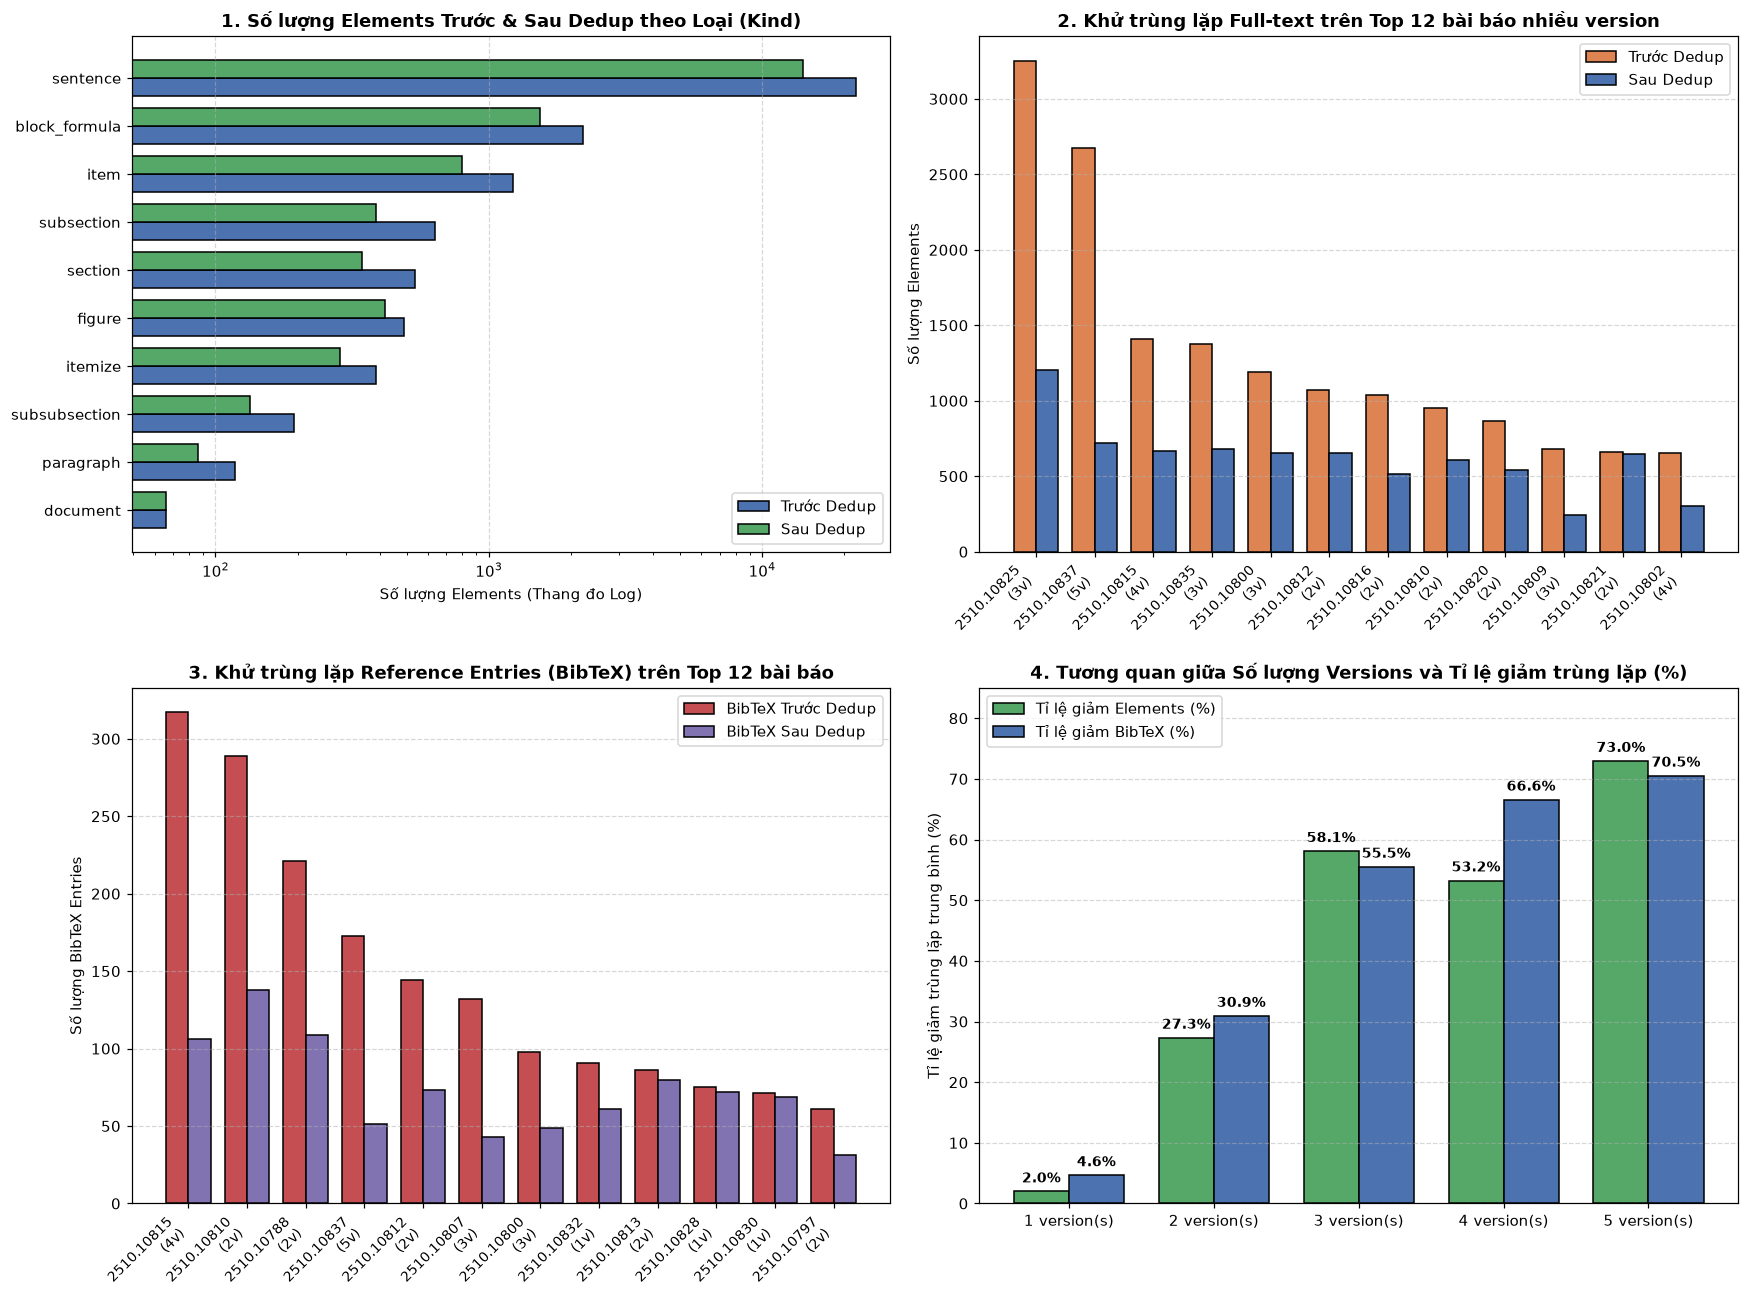

In [4]:
# Trực quan hóa 4 biểu đồ đánh giá hiệu quả Khử trùng lặp (Deduplication)
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.dpi"] = 110
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Biểu đồ 1: So sánh số lượng Elements Trước vs Sau Dedup theo từng Kind (Log Scale)
ax1 = axes[0, 0]
y_pos = np.arange(len(df_kinds_dedup))
height = 0.38
ax1.barh(y_pos + height / 2, df_kinds_dedup["Trước Dedup"], height, label="Trước Dedup", color="#4C72B0", edgecolor="black")
ax1.barh(y_pos - height / 2, df_kinds_dedup["Sau Dedup"], height, label="Sau Dedup", color="#55A868", edgecolor="black")
ax1.set_yticks(y_pos)
ax1.set_yticklabels(df_kinds_dedup["Loại phần tử (Kind)"])
ax1.invert_yaxis()
ax1.set_xscale("log")
ax1.set_xlabel("Số lượng Elements (Thang đo Log)")
ax1.set_title("1. Số lượng Elements Trước & Sau Dedup theo Loại (Kind)", fontsize=12, fontweight="bold")
ax1.legend()
ax1.grid(axis="x", linestyle="--", alpha=0.5)

# iểu đồ 2: Hiệu quả giảm trùng lặp Full-text trên các bài báo nhiều version tiêu biểu
ax2 = axes[0, 1]
active_multi = df_multi_ver[df_multi_ver["Elements (Trước)"] > 0].sort_values(by="Elements (Trước)", ascending=False).head(12)
x2 = np.arange(len(active_multi))
width = 0.38
ax2.bar(x2 - width / 2, active_multi["Elements (Trước)"], width, label="Trước Dedup", color="#DD8452", edgecolor="black")
ax2.bar(x2 + width / 2, active_multi["Elements (Sau)"], width, label="Sau Dedup", color="#4C72B0", edgecolor="black")
ax2.set_xticks(x2)
ax2.set_xticklabels([f"{r['arXiv ID']}\n({r['Số Versions']}v)" for _, r in active_multi.iterrows()], rotation=45, ha="right", fontsize=9)
ax2.set_ylabel("Số lượng Elements")
ax2.set_title("2. Khử trùng lặp Full-text trên Top 12 bài báo nhiều version", fontsize=12, fontweight="bold")
ax2.legend()
ax2.grid(axis="y", linestyle="--", alpha=0.5)

# Biểu đồ 3: Hiệu quả khử trùng lặp Reference Entries (BibTeX) trên các bài báo tiêu biểu
ax3 = axes[1, 0]
all_pubs_df = pd.DataFrame([
    {
        "arXiv ID": p["arxiv_id"],
        "versions": p["total_versions"],
        "bib_before": p["bibtex_dedup"]["total_raw_entries"],
        "bib_after": p["bibtex_dedup"]["dedup_entries_count"],
        "bib_red_pct": p["bibtex_dedup"]["reduction_percentage"],
        "elem_red_pct": p["elements_dedup"]["reduction_percentage"],
    }
    for p in summary_data["publications"]
])
top_bib = all_pubs_df[all_pubs_df["bib_before"] > all_pubs_df["bib_after"]].sort_values(by="bib_before", ascending=False).head(12)
x3 = np.arange(len(top_bib))
ax3.bar(x3 - width / 2, top_bib["bib_before"], width, label="BibTeX Trước Dedup", color="#C44E52", edgecolor="black")
ax3.bar(x3 + width / 2, top_bib["bib_after"], width, label="BibTeX Sau Dedup", color="#8172B2", edgecolor="black")
ax3.set_xticks(x3)
ax3.set_xticklabels([f"{r['arXiv ID']}\n({r['versions']}v)" for _, r in top_bib.iterrows()], rotation=45, ha="right", fontsize=9)
ax3.set_ylabel("Số lượng BibTeX Entries")
ax3.set_title("3. Khử trùng lặp Reference Entries (BibTeX) trên Top 12 bài báo", fontsize=12, fontweight="bold")
ax3.legend()
ax3.grid(axis="y", linestyle="--", alpha=0.5)

# Biểu đồ 4: Tỉ lệ giảm trùng lặp trung bình (%) theo Số lượng Versions của bài báo
ax4 = axes[1, 1]
tex_pubs = [p for p in summary_data["publications"] if p["tex_versions"] > 0]
ver_groups = sorted({p["total_versions"] for p in tex_pubs})
avg_elem_red = []
avg_bib_red = []
for v_cnt in ver_groups:
    sub_e = [p["elements_dedup"]["reduction_percentage"] for p in tex_pubs if p["total_versions"] == v_cnt]
    sub_b = [p["bibtex_dedup"]["reduction_percentage"] for p in tex_pubs if p["total_versions"] == v_cnt and p["bibtex_dedup"]["total_raw_entries"] > 0]
    avg_elem_red.append(np.mean(sub_e) if sub_e else 0.0)
    avg_bib_red.append(np.mean(sub_b) if sub_b else 0.0)

x4 = np.arange(len(ver_groups))
ax4.bar(x4 - width / 2, avg_elem_red, width, label="Tỉ lệ giảm Elements (%)", color="#55A868", edgecolor="black")
ax4.bar(x4 + width / 2, avg_bib_red, width, label="Tỉ lệ giảm BibTeX (%)", color="#4C72B0", edgecolor="black")
ax4.set_xticks(x4)
ax4.set_xticklabels([f"{v} version(s)" for v in ver_groups])
ax4.set_ylabel("Tỉ lệ giảm trùng lặp trung bình (%)")
ax4.set_ylim(0, 85)
ax4.set_title("4. Tương quan giữa Số lượng Versions và Tỉ lệ giảm trùng lặp (%)", fontsize=12, fontweight="bold")
for i, (ve, vb) in enumerate(zip(avg_elem_red, avg_bib_red)):
    ax4.text(i - width / 2, ve + 1.5, f"{ve:.1f}%", ha="center", fontsize=9, fontweight="bold")
    ax4.text(i + width / 2, vb + 1.5, f"{vb:.1f}%", ha="center", fontsize=9, fontweight="bold")
ax4.legend()
ax4.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()